# 02 · Challenge 2 — the Darwinian threshold

**Review claim (Bozdag et al., Fig. 3):** to become units of selection, groups need a life cycle
(growth + reproduction) and heritable group-level traits. Neither has to be evolved first: the life
cycle can be *scaffolded* by physics (packing stress fragments snowflake yeast) or by the environment
(periodic flooding of *Jeongeupia sacculi* cave mats; alternating selection in *Pseudomonas*), and
group traits can emerge from cell traits with **higher heritability than the cell traits themselves**
(Zamani-Dahaj et al. 2023), or as non-additive collective behaviour (*Choanoeca flexa* inversion).

We test each claim with the minimal-chemistry cells of notebooks 00–01:

| Section | Mechanism | What is measured |
|---|---|---|
| A | Biophysical scaffolding | life cycle of a snowflake cluster: growth → packing fracture → clonal propagule |
| B | Emergent heritability | $H^2$ of cell aspect ratio vs $H^2$ of cluster size at fracture |
| C | Selection on the emergent trait | settling selection on size drives cell elongation (MuLTEE-like) |
| D | Ecological scaffolding | patches + floods make a costly "matrix" species spread; fitness decoupling |
| E | Emergent collective behaviour | sheet inversion from uncoupled cell switches |

Run time: ~8–12 min on a 4-core laptop (`FAST = True`: ~4 min).

In [1]:
import os, time, numpy as np, matplotlib.pyplot as plt
from protoevo import Chem, ancestral_state, run_parallel
import nb2_model as m2
from nb1_model import setup_chemistry
os.makedirs('figures', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FAST = False
N_JOBS = None
t_start = time.time()

chem = Chem(N=30, seed=1)
anc = ancestral_state(chem); s0 = chem.state(anc)
elong = m2.robust_active_node(chem, s0)
print('elongation species:', elong, '(active in the ancestor; its dips do not flip the network)')

elongation species: 0 (active in the ancestor; its dips do not flip the network)


## A · A life cycle "for free" (biophysical scaffolding)
Daughters never separate (the separase is already off, as at the end of notebook 01). Each cell's
aspect ratio is fixed at birth by the concentration of an "elongation" species,
$\mathrm{AR} = 1 + X_e$, which fluctuates through demographic noise. The cluster is a branching tree;
when it exceeds $n^* = n_0\langle \mathrm{AR}\rangle^{\beta}$ cells (elongated cells pack more loosely,
so stress builds later; Jacobeen et al. 2018) a bond breaks and a whole branch — a clonal, multicellular
propagule — is released. Nobody programmed reproduction: it follows from growth plus packing.

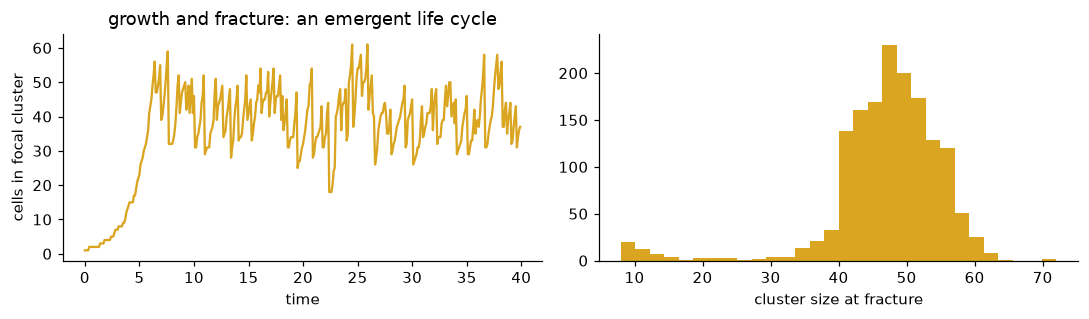

In [2]:
r = m2.snowflake_lineages(chem, anc, elong, 1.0, n_groups=1, T=40, seed=1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
tt = np.arange(len(r['size_trace'])) * 10 * chem.dt
ax[0].plot(tt, r['size_trace'], c='goldenrod'); ax[0].set_xlabel('time'); ax[0].set_ylabel('cells in focal cluster')
ax[0].set_title('growth and fracture: an emergent life cycle')
rr = m2.snowflake_lineages(chem, anc, elong, 1.0, n_groups=30, T=30, seed=2)
ax[1].hist(rr['frac_size'], bins=30, color='goldenrod'); ax[1].set_xlabel('cluster size at fracture')
plt.tight_layout(); plt.savefig('figures/02_lifecycle.png'); plt.show()

## B · Group-level heritability exceeds cell-level heritability
Five "genotypes" differ in the catalytic supply $\Lambda_e$ of the elongation reaction. For each we record
every cell's aspect ratio and every cluster's size at fracture, then compute broad-sense heritability
$H^2 = \mathrm{Var}(\text{genotype means})/\mathrm{Var}(\text{all})$, for two levels of demographic noise.

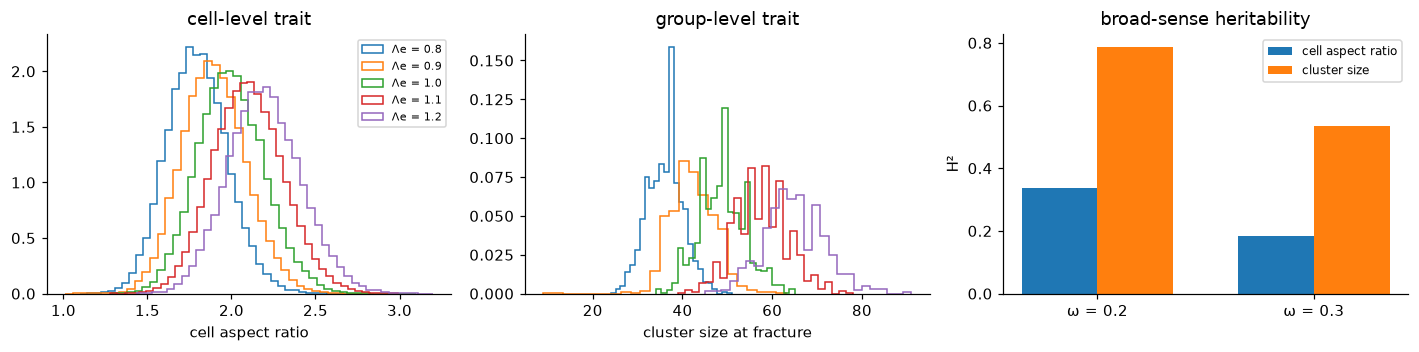

ω = 0.2:  H²(cell AR) = 0.34   H²(cluster size) = 0.79
ω = 0.3:  H²(cell AR) = 0.18   H²(cluster size) = 0.53


In [3]:
genotypes = [0.8, 0.9, 1.0, 1.1, 1.2]
omegas = [0.2, 0.3]
jobs = [dict(Le=L, omega=om, T=20 if FAST else 30, seed=10 * i + j)
        for j, om in enumerate(omegas) for i, L in enumerate(genotypes)]
out = run_parallel(m2.h2_job, jobs, N_JOBS)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
H = {}
for j, om in enumerate(omegas):
    rs = out[j * len(genotypes):(j + 1) * len(genotypes)]
    H[om] = (m2.broad_sense_H2([x['AR'] for x in rs]),
             m2.broad_sense_H2([x['frac_size'].astype(float) for x in rs]))
    if j == 0:
        for L, x in zip(genotypes, rs):
            ax[0].hist(x['AR'], bins=40, histtype='step', density=True, label=f'Λe = {L}')
            ax[1].hist(x['frac_size'], bins=25, histtype='step', density=True)
ax[0].set_xlabel('cell aspect ratio'); ax[0].legend(fontsize=7); ax[0].set_title('cell-level trait')
ax[1].set_xlabel('cluster size at fracture'); ax[1].set_title('group-level trait')
w = 0.35
ax[2].bar(np.arange(2) - w / 2, [H[o][0] for o in omegas], w, label='cell aspect ratio')
ax[2].bar(np.arange(2) + w / 2, [H[o][1] for o in omegas], w, label='cluster size')
ax[2].set_xticks(range(2)); ax[2].set_xticklabels([f'ω = {o}' for o in omegas]); ax[2].set_ylabel('H²')
ax[2].legend(fontsize=8); ax[2].set_title('broad-sense heritability')
plt.tight_layout(); plt.savefig('figures/02_heritability.png'); plt.show()
for o in omegas: print(f'ω = {o}:  H²(cell AR) = {H[o][0]:.2f}   H²(cluster size) = {H[o][1]:.2f}')

The genotype changes only a cellular property, yet the cluster-level trait is *more* heritable: the
cluster integrates the noisy shapes of dozens of cells, averaging out demographic noise, exactly the
mechanism proposed by Zamani-Dahaj et al. More cellular noise widens the gap.

## C · Selection on the emergent group trait (MuLTEE-like)
Now $\Lambda_e$ mutates at division (10% of divisions, ±10%), and each day the fastest-settling
clusters are transferred. Selection acts on *cluster size*, but the response appears in *cell shape*.

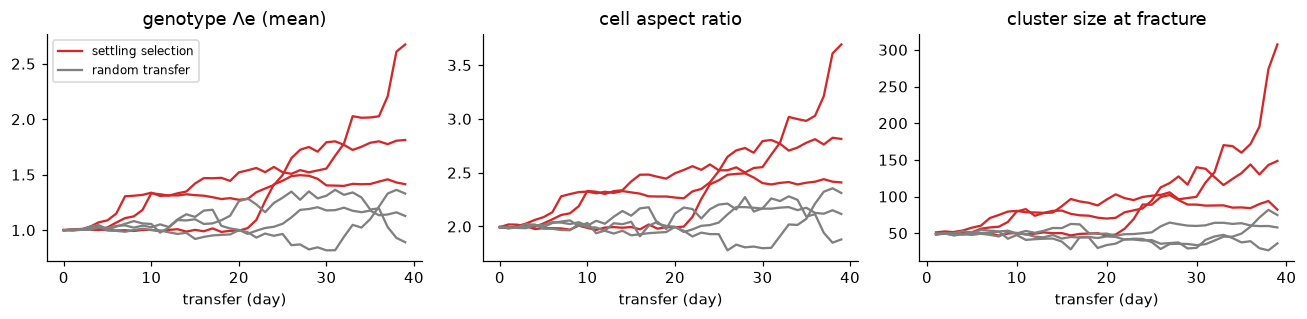

In [4]:
jobs = [dict(selection=s, seed=s_) for s in ['settle', 'none'] for s_ in range(3)]
out = run_parallel(m2.multee_job, [dict(j, days=25 if FAST else 40) for j in jobs], N_JOBS)
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for j, h in zip(jobs, out):
    c = 'tab:red' if j['selection'] == 'settle' else 'gray'
    ax[0].plot(h['Lam_e'], c=c); ax[1].plot(h['AR'], c=c); ax[2].plot(h['n_frac_size'], c=c)
for a, t in zip(ax, ['genotype Λe (mean)', 'cell aspect ratio', 'cluster size at fracture']):
    a.set_title(t); a.set_xlabel('transfer (day)')
ax[0].plot([], [], c='tab:red', label='settling selection'); ax[0].plot([], [], c='gray', label='random transfer')
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig('figures/02_multee.png'); plt.show()

## D · Ecological scaffolding: floods make patches into Darwinian individuals
Cells live on a cave wall in patches. A compositional "matrix" species $m$ (inactive in the ancestor,
one switch away) makes a cell grow 30% slower, but holds the patch together: when the flood comes, a
patch releases dispersers in proportion to $n_\text{cells}(b_0 + f_m)$, where $f_m$ is its fraction of
matrix producers. Dispersers found new patches — with **1, 2, 4 or 8 founders** — or, in the
**no-scaffold** control, the population is one well-mixed pool where dispersal success is shared.

Nothing about cells changes between treatments; only the environmental rhythm (bottleneck → growth →
dispersal) differs, as proposed by Black, Bourrat & Rainey (2020).

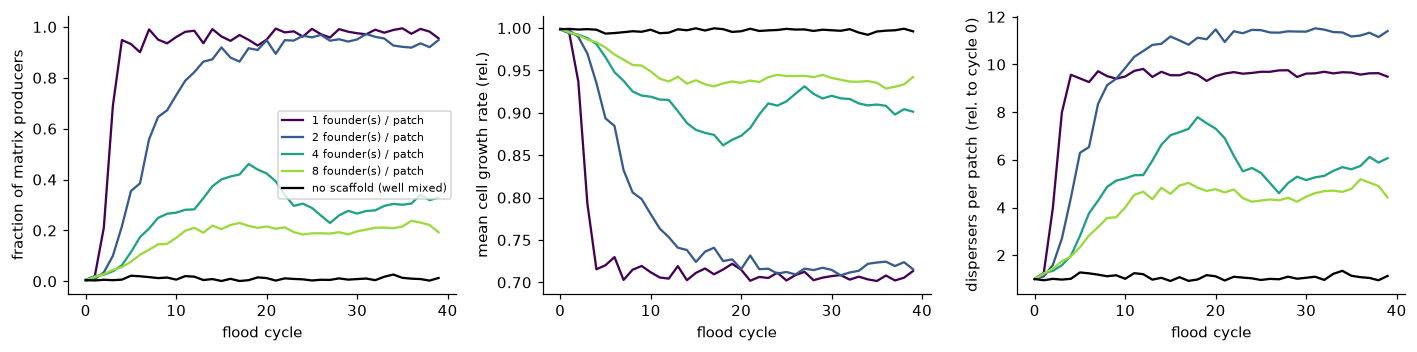

In [5]:
founders = [1, 2, 4] if FAST else [1, 2, 4, 8]
CYC = 30 if FAST else 40
jobs = [dict(founders=f, well_mixed=False, cycles=CYC, seed=0) for f in founders] + \
       [dict(founders=1, well_mixed=True, cycles=CYC, seed=0)]
out = run_parallel(m2.scaffold_job, jobs, N_JOBS)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
cm = plt.cm.viridis(np.linspace(0, .85, len(founders)))
for j, h in zip(jobs, out):
    lab = 'no scaffold (well mixed)' if j['well_mixed'] else f"{j['founders']} founder(s) / patch"
    c = 'k' if j['well_mixed'] else cm[founders.index(j['founders'])]
    ax[0].plot(h['f_m'], c=c, label=lab)
    ax[1].plot(h['cell_growth'], c=c); ax[2].plot(h['group_output'] / h['group_output'][0], c=c)
ax[0].set_ylabel('fraction of matrix producers'); ax[0].legend(fontsize=7)
ax[1].set_ylabel('mean cell growth rate (rel.)'); ax[2].set_ylabel('dispersers per patch (rel. to cycle 0)')
for a in ax: a.set_xlabel('flood cycle')
plt.tight_layout(); plt.savefig('figures/02_scaffolding.png'); plt.show()

**Fitness decoupling.** With single-cell bottlenecks the matrix species sweeps: cell-level growth
*falls* while patch-level reproduction *rises* — fitness has been transferred to the group. As founders
per patch increase, between-patch variation is diluted, non-producers win inside mixed patches, and the
matrix species settles at intermediate frequency; without the scaffold only cell-level selection acts and
it stays near zero (mutation–selection balance).

**Group-level heredity.** With single founders, a daughter patch's matrix fraction is predicted by its
parent patch's — a parent–offspring regression at the level of patches.

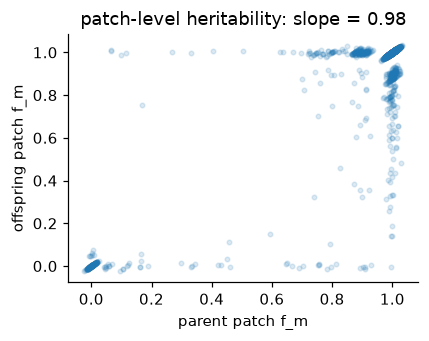

In [6]:
h1 = out[0]
pp, pc = h1['po_parent'], h1['po_child']
slope = np.polyfit(pp, pc, 1)[0]
plt.figure(figsize=(4, 3.2))
jit = np.random.default_rng(0).normal(0, 0.01, len(pp))
plt.plot(pp + jit, pc + jit, '.', alpha=.15); plt.xlabel('parent patch f_m'); plt.ylabel('offspring patch f_m')
plt.title(f'patch-level heritability: slope = {slope:.2f}'); plt.tight_layout()
plt.savefig('figures/02_patch_heritability.png'); plt.show()

## E · Collective behaviour without communication (*C. flexa*)
Each cell carries a two-species version of the network — mutually inhibiting "relaxed collar" and
"contracted collar" species (paper Fig. 1 with $N=2$). Darkness shifts catalytic supply between them.
Cells do **not** exchange molecules. The cup-shaped sheet is a bistable shell: it snaps to the inverted,
swimming configuration when more than half the collars are contracted.

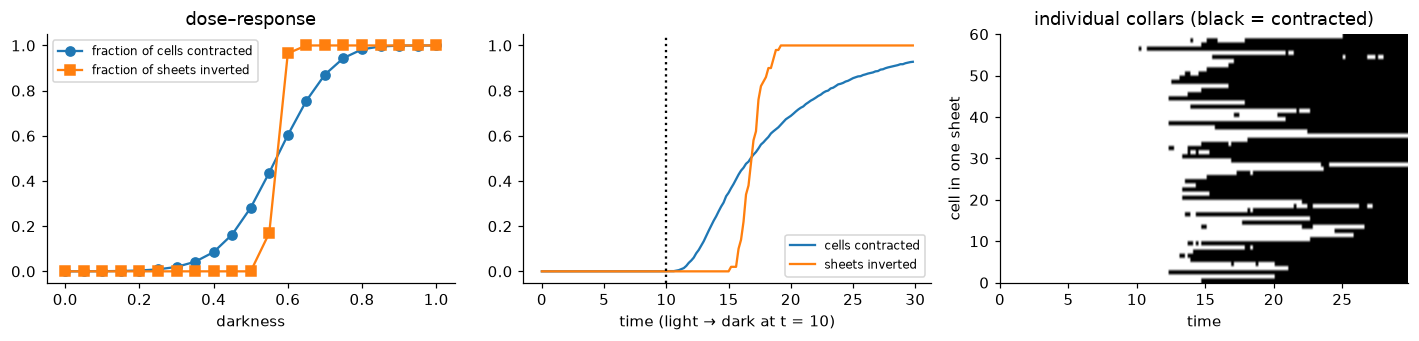

total run time: 311 s


In [7]:
dark = np.linspace(0, 1, 21)
cell_resp, sheet_resp, sheet_sd = [], [], []
for d in dark:
    tr = m2.flexa_sheet(d, n_sheets=100 if FAST else 200, T=30, seed=1)
    cell_resp.append(tr[-1][1]); sheet_resp.append(tr[-1][2]); sheet_sd.append(tr[-1][4].std())
step = lambda t: 0.0 if t < 10 else 0.8
tr = m2.flexa_sheet(step, n_cells=60, n_sheets=50, T=30, seed=2)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(dark, cell_resp, 'o-', label='fraction of cells contracted')
ax[0].plot(dark, sheet_resp, 's-', label='fraction of sheets inverted')
ax[0].set_xlabel('darkness'); ax[0].legend(fontsize=8); ax[0].set_title('dose–response')
t = [x[0] for x in tr]
ax[1].plot(t, [x[1] for x in tr], label='cells contracted'); ax[1].plot(t, [x[2] for x in tr], label='sheets inverted')
ax[1].axvline(10, c='k', ls=':'); ax[1].set_xlabel('time (light → dark at t = 10)'); ax[1].legend(fontsize=8)
ax[2].imshow(np.array([x[3] for x in tr]).T, aspect='auto', cmap='Greys',
             extent=[t[0], t[-1], 0, 60]); ax[2].set_xlabel('time'); ax[2].set_ylabel('cell in one sheet')
ax[2].set_title('individual collars (black = contracted)')
plt.tight_layout(); plt.savefig('figures/02_flexa.png'); plt.show()
print(f'total run time: {time.time() - t_start:.0f} s')

Individual cells respond gradually and noisily; the sheet responds all-or-none and on cue, because
the group-level variable (inversion) integrates every cell. The collective trait is a non-additive,
emergent property of cell-level changes — no signalling, no differentiation.

## Reading the results against the review
* **Life cycles need not be evolved first.** Packing physics (A) or an environmental rhythm (D) supplies
  group growth and reproduction, with single-cell or single-branch bottlenecks that keep groups clonal.
* **Group traits are heritable — more than their cellular basis.** (B) Averaging over cells beats the
  cellular noise that the minimal chemistry inevitably produces.
* **Selection then acts on the group.** (C) selection on cluster size reshapes cells; (D) a trait that is
  costly to cells spreads because it benefits patches — fitness decoupling, the hallmark of a transition
  in individuality — but only when the scaffold imposes bottlenecks.
* **Emergent collective behaviour.** (E) a coordinated group-level switch arises from uncoupled cell switches.